In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [11]:
matrix = np.random.randint(0,100, size= (5,5)) #generate rand integers between 0 and 100 of size 5,5

row_means = matrix.mean (axis =1) #calculate mean. important bit is axis=1 : go across each row, through its columns return result then next


column_means = matrix.mean (axis=0) #axis=0 :go down each col, calculate, return result and then next.


overall_std = matrix.std()


print("Matrix:")
print(matrix)

print("\nRow means:")
print(row_means)

print("\nColumn means:")
print(column_means)

print("\nOverall standard deviation:")
print(overall_std)


Matrix:
[[92 56  3 97 52]
 [32 22 68 86 29]
 [82 26 69 81 33]
 [ 3 85 97 71  7]
 [ 7 61  7 92 42]]

Row means:
[60.  47.4 58.2 52.6 41.8]

Column means:
[43.2 50.  48.8 85.4 32.6]

Overall standard deviation:
32.29984520086745


In [12]:
#numpy drill 2
matrx_drill2 = matrix.copy()
matrx_drill2 [matrx_drill2 > 75] = -1 #matrix_drill2 > 75 creates a boolean matrix, and then wherever its true replace with -1
print ("\nMatrix after replacing")
print (matrx_drill2)



Matrix after replacing
[[-1 56  3 -1 52]
 [32 22 68 -1 29]
 [-1 26 69 -1 33]
 [ 3 -1 -1 71  7]
 [ 7 61  7 -1 42]]


In [20]:
arr = np.arange(1,101) #1d array from 1 to 100
moving_avg = (arr[:-2] + arr[1:-1] + arr[2:]) / 3
print(moving_avg)


[ 2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18. 19.
 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35. 36. 37.
 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48. 49. 50. 51. 52. 53. 54. 55.
 56. 57. 58. 59. 60. 61. 62. 63. 64. 65. 66. 67. 68. 69. 70. 71. 72. 73.
 74. 75. 76. 77. 78. 79. 80. 81. 82. 83. 84. 85. 86. 87. 88. 89. 90. 91.
 92. 93. 94. 95. 96. 97. 98. 99.]


In [ ]:
#pandas drill
import seaborn as sns #seaborn is a visualization/data library, using it here to give us easy sample datasets.
titanic = sns.load_dataset ("titanic")
titanic.head() #show first 5lines

rows,cols = titanic.shape
age_dtype = titanic["age"].dtype #its float since missing values represented as NaN which is a float

print ("\nRows: ", rows)
print ("\ncols: ", cols)
print ("\nage_dtype: ", age_dtype)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [23]:
#Group by class and sex

survival_by_class_sex = titanic.groupby(["class", "sex"])["survived"].mean().reset_index() #split the table into groups based on passenger class and sex, then for each group we look at survived which is a col in the titanic ds. then we calculate the mean for each group
survival_by_class_sex


C:\Users\ramia\AppData\Local\Temp\ipykernel_29160\3222394537.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  survival_by_class_sex = titanic.groupby(["class", "sex"])["survived"].mean().reset_index() #split the table into groups based on passenger class and sex, then for each group we look at survived which is a col in the titanic ds. then we calculate the mean for each group


,class,sex,survived
0,First,female,0.968085
1,First,male,0.368852
2,Second,female,0.921053
3,Second,male,0.157407
4,Third,female,0.500000
5,Third,male,0.135447


In [24]:
#pandas drill 3
missing_before = titanic["age"].isna().sum() #get the age column, make a column with true false values, false if age is empty, then sum() counts the number of true values

class_median_age = titanic.groupby ("class")["age"].transform ("median") #class_median_age is a col which answers for each row, what age should I use if this passengers age is missing

titanic["age_filled"] = titanic["age"].fillna(class_median_age) #If the original age is not missing, copy it as is. If the original age is missing, use the value from class_median_age at the same row

missing_after = titanic["age_filled"].isna().sum()

print("Missing age values before:", missing_before)

print("Missing age values after:", missing_after)

titanic.head(10)


Missing age values before: 177
Missing age values after: 0


C:\Users\ramia\AppData\Local\Temp\ipykernel_29160\3344990013.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  class_median_age = titanic.groupby ("class")["age"].transform ("median") #class_median_age is a col which answers for each row, what age should I use if this passengers age is missing


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_filled
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,22.0
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,38.0
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,26.0
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,35.0
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,35.0
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True,24.0
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True,54.0
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False,2.0
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False,27.0
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False,14.0


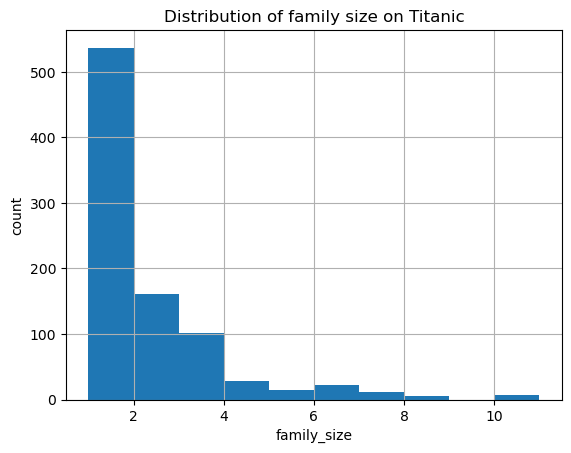

In [26]:
titanic["family_size"] = titanic["sibsp"] + titanic["parch"] + 1 #adds row by row respetcively and saves it in a new col
titanic["family_size"].hist() #select col and plot it

plt.xlabel ("family_size")
plt.ylabel ("count")
plt.title("Distribution of family size on Titanic")
plt.show()

In [1]:
#database primer
import sqlite3
import pandas as pd

df = pd.DataFrame({ #create a pandas table manually with 2 cols review and sentitment. df = table
    "review": [
        "This movie was amazing",
        "The film was boring",
        "I loved the acting",
        "Terrible story and bad pacing",
        "Excellent movie overall",
        "Waste of time"
    ],
    "sentiment": [
        "positive",
        "negative",
        "positive",
        "negative",
        "positive",
        "negative"
    ]
})

con = sqlite3.connect ("../reviews.db")
#takes pandas df to sql. reviews is the table name inside db, if exists = if a table called reviews exists replace
df.to_sql ("reviews", con, if_exists="replace", index=False)

pd.read_sql ("SELECT sentiment, COUNT(*) AS n FROM reviews GROUP BY sentiment;",
    con)

,sentiment,n
0,negative,3
1,positive,3
